# DataWorksMD Social Network Analysis
**Ian McCulloh, Ph.D.**  
*15 May 2018*  

This notebook demonstrates basic social network analysis using the `igraph` package in R.

---

## 1. Install and Load Required Packages

In [1]:
# Install igraph if not already installed (uncomment to run once)
install.packages("igraph")

# Load required libraries
library(igraph)
library(data.table)
library(cluster)

cat("Packages loaded successfully!\n")

Installing package into 'C:/Users/Shane/AppData/Local/R/win-library/4.6'
(as 'lib' is unspecified)



package 'igraph' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Shane\AppData\Local\Temp\RtmpMRZ3aB\downloaded_packages


Warning message:
"package 'igraph' was built under R version 4.6.2"

Attaching package: 'igraph'


The following objects are masked from 'package:stats':

    decompose, spectrum


The following object is masked from 'package:base':

    union



Attaching package: 'data.table'


The following object is masked from 'package:base':

    %notin%




Packages loaded successfully!


## 2. Basic Network Creation

[1] "igraph"

IGRAPH d4b9ba6 U--- 3 3 -- 
+ edges from d4b9ba6:
[1] 1--2 2--3 1--3


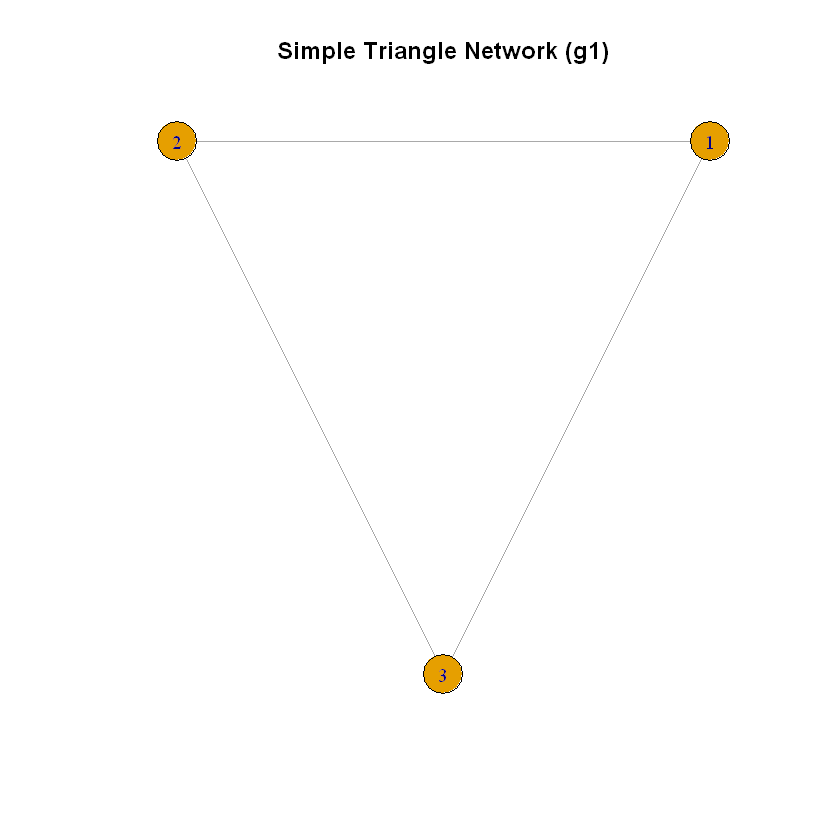

In [2]:
# Simple triangle network with 3 nodes
g1 <- make_graph(edges = c(1, 2, 2, 3, 3, 1), n = 3, directed = FALSE)
plot(g1, main = "Simple Triangle Network (g1)")

# Check class and structure
class(g1)
print(g1)

Warning message:
"`graph()` was deprecated in igraph 2.1.0.
ℹ Please use `make_graph()` instead."


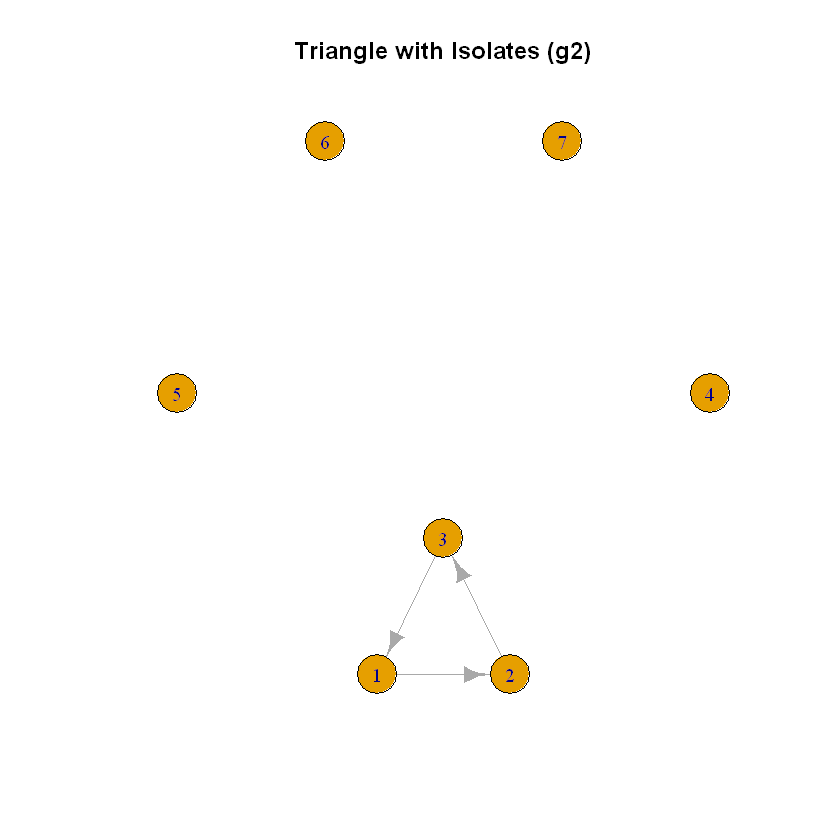

In [3]:
# Same edges, but with 7 total nodes (isolates will appear)
g2 <- graph(edges = c(1, 2, 2, 3, 3, 1), n = 7)
plot(g2, main = "Triangle with Isolates (g2)")

## 3. Named Nodes and Isolates

In [ ]:
# Network with named nodes
g3 <- graph(edges = c("Alex", "Bill", "Bill", "Carl", "Carl", "Alex"))
plot(g3, main = "Named Triangle (g3)")

In [ ]:
# Add isolated nodes
g4 <- graph(
  edges = c("Alex", "Bill", "Bill", "Carl", "Carl", "Alex"),
  isolates = c("Dave", "Eric", "Frank", "Greg")
)

plot(
  g4,
  edge.arrow.size = .5,
  vertex.color = "red",
  vertex.size = 10,
  vertex.frame.color = "gray",
  vertex.label.color = "black",
  vertex.label.cex = 1.2,
  vertex.label.dist = 2,
  edge.curved = 0.2,
  main = "Styled Network with Isolates (g4)"
)

## 4. Complex Network from Literal Syntax

In [ ]:
# Create a more complex graph using literal syntax
g5 <- graph_from_literal(
  a-b-c-d-e, a-h-g-i-b, a-g, h-i, d-j:k:l, e-l:k
)
plot(g5, main = "Complex Network (g5)")

## 5. Inspect the Graph

In [ ]:
# Edges, vertices, adjacency matrix
cat("Edges:\n")
print(E(g5))

cat("\nVertices:\n")
print(V(g5))

cat("\nAdjacency Matrix:\n")
print(g5[])

cat("\nVertex Names:\n")
print(V(g5)$name)

## 6. Add Vertex Attributes (Gender)

In [ ]:
# Assign gender attribute
V(g5)$gender <- c("m", "f", "m", "f", "m", "m", "f", "f", "m", "m", "m")

# Plot with color by gender
plot(
  g5,
  edge.arrow.size = .5,
  vertex.label.color = "black",
  vertex.label.dist = 1.5,
  vertex.color = c("pink", "blue")[1 + (V(g5)$gender == "m")],
  main = "Network Colored by Gender"
)

## 7. Network Metrics

In [ ]:
# Density
dens <- edge_density(g5, loops = FALSE)
cat("Network Density:", round(dens, 4), "\n")

In [ ]:
# Diameter
diam <- diameter(g5, directed = FALSE, weights = NA)
cat("Diameter:", diam, "\n")

d_path <- get_diameter(g5, directed = FALSE, weights = NA)
cat("\nDiameter Path Nodes:\n")
print(d_path)

In [ ]:
# Highlight diameter path
vcol <- rep("gray40", vcount(g5))
vcol[d_path] <- "red"
ecol <- rep("gray80", ecount(g5))
ecol[E(g5, path = d_path)] <- "orange"

plot(
  g5,
  vertex.color = vcol,
  edge.color = ecol,
  edge.arrow.mode = 0,
  main = "Diameter Path Highlighted"
)

## 8. Centrality Measures

In [ ]:
# Degree Centrality
deg <- degree(g5, mode = "all")
plot(g5, vertex.size = deg * 5, main = "Node Size by Degree Centrality")

hist(deg, breaks = 1:vcount(g5) - 1, main = "Histogram of Degree", xlab = "Degree")

In [ ]:
# Closeness Centrality
clo1 <- closeness(g5, mode = "all", weights = NA)
clo2 <- centr_clo(g5, mode = "all", normalized = TRUE)

par(mfrow = c(1, 2))
plot(g5, vertex.size = clo1 * 300, main = "Closeness (Raw)")
plot(g5, vertex.size = clo2$res * 30, main = "Closeness (Normalized)")
par(mfrow = c(1, 1))

print(clo2)

In [ ]:
# Eigenvector Centrality
e <- eigen_centrality(g5, directed = TRUE, weights = NA)
cat("Eigenvector Centrality Scores:\n")
print(round(e$vector, 4))

In [ ]:
# Betweenness Centrality
b <- betweenness(g5, directed = FALSE, weights = NA)
plot(g5, vertex.size = b / 2 + 5, main = "Node Size by Betweenness")
cat("\nBetweenness Scores:\n")
print(round(b, 2))

## 9. Clustering and Community Detection

In [ ]:
# Cliques
cliq <- cliques(g5)
cat("Number of cliques:", length(cliq), "\n")

lg_cliq <- largest_cliques(g5)
cat("Largest clique(s) size:", length(lg_cliq[[1]]), "\n")

# Highlight largest clique
vcol <- rep("grey80", vcount(g5))
vcol[unlist(largest_cliques(g5))] <- "gold"

plot(
  as.undirected(g5),
  vertex.label = V(g5)$name,
  vertex.color = vcol,
  main = "Largest Clique(s) in Gold"
)

In [ ]:
# Newman (Edge Betweenness) Community Detection
g5.new <- cluster_edge_betweenness(g5)
plot(g5.new, g5, main = "Edge Betweenness Communities")

cat("Number of communities:", length(g5.new), "\n")
cat("Membership:\n")
print(membership(g5.new))
cat("Modularity:", round(modularity(g5.new), 4), "\n")

In [ ]:
# Louvain Community Detection
cl <- cluster_louvain(g5, weights = NULL)
plot(cl, g5, main = "Louvain Communities")

cat("Number of communities:", length(cl), "\n")
cat("Membership:\n")
print(membership(cl))
cat("Modularity:", round(modularity(cl), 4), "\n")

---
## Summary

This notebook covers:
- Creating networks in `igraph`
- Visual styling and attributes
- Core metrics: density, diameter, centrality
- Community detection: cliques, Newman, Louvain

Feel free to modify `g5` or load your own data for analysis!

*Notebook adapted from original R script by Ian McCulloh, Ph.D.*